# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import SECONDDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

### Multilabel masks

Total number of patches: 2968


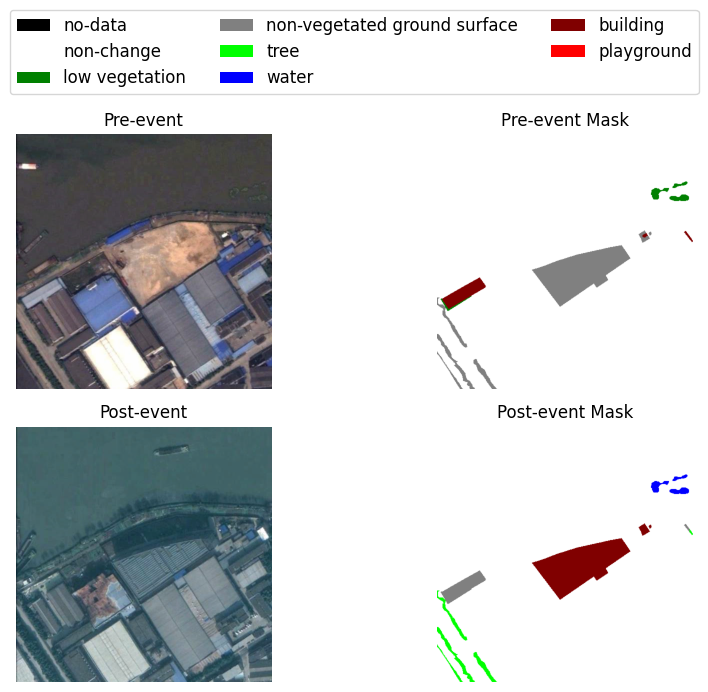

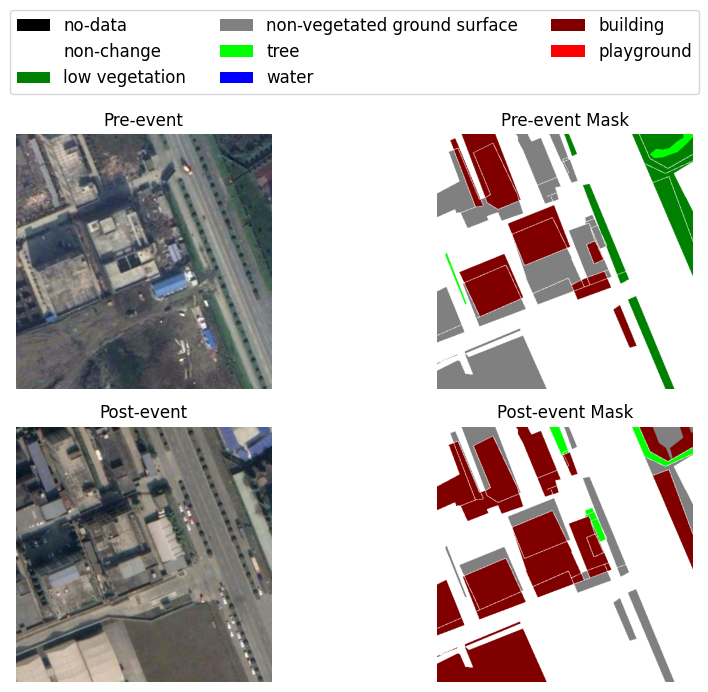

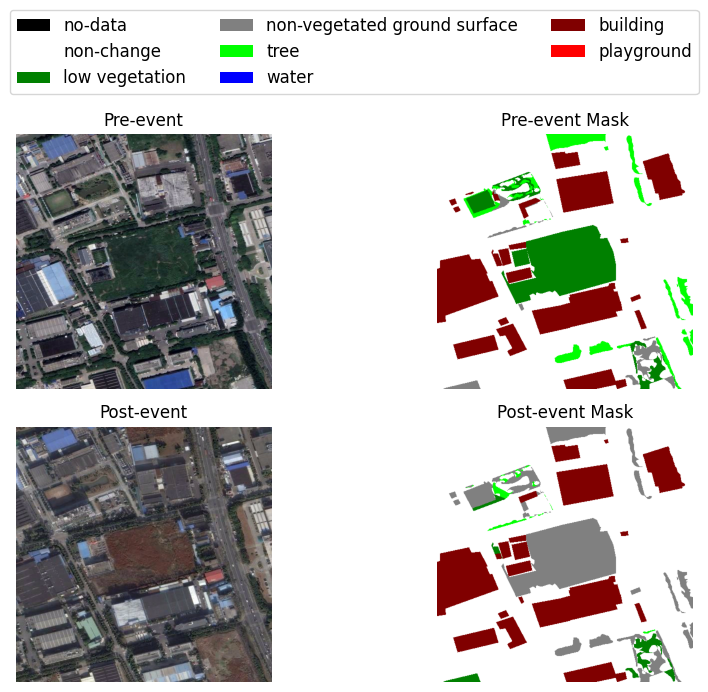

In [ ]:
dataset_config = {
    "data_dir" : "./data/second/SECOND_train_set/",
    "task_type": "multilabel"
}
dataset = SECONDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(22);

In [62]:
dataset.data_distribution_table()

,Number of pixels
non-change,1.245811e+09
low vegetation,7.684417e+07
non-vegetated ground surface,1.117671e+08
tree,2.427789e+07
water,4.087934e+06
building,9.140711e+07
playground,1.891665e+06


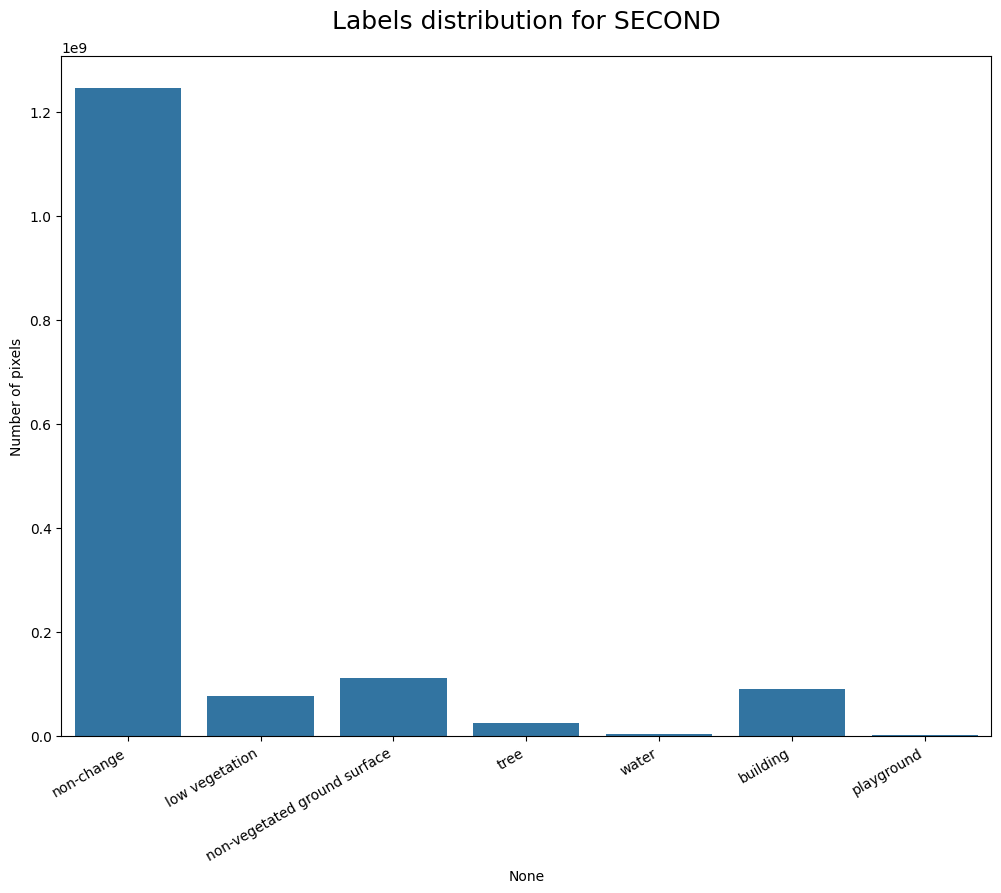

In [63]:
dataset.data_distribution_barchart();

### Binary masks

Total number of patches: 2968


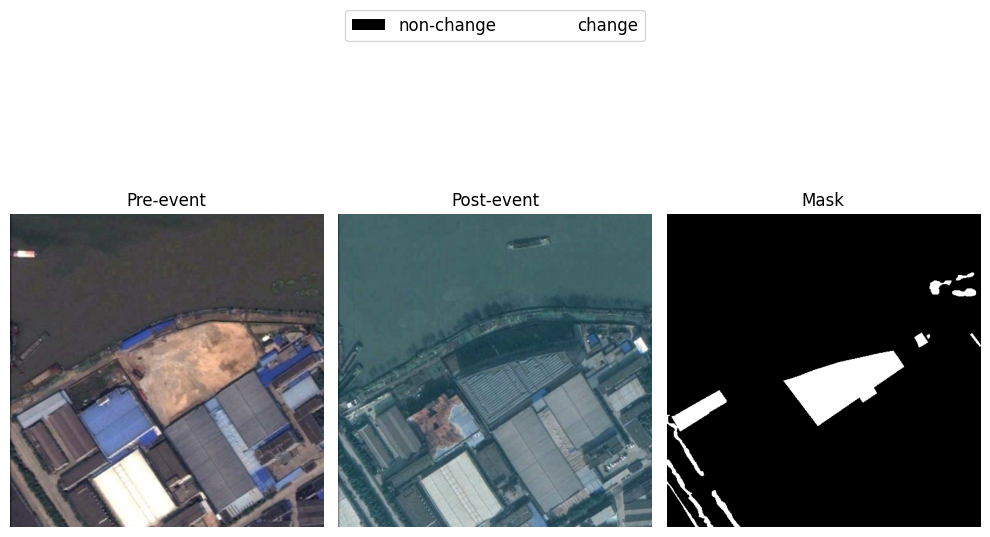

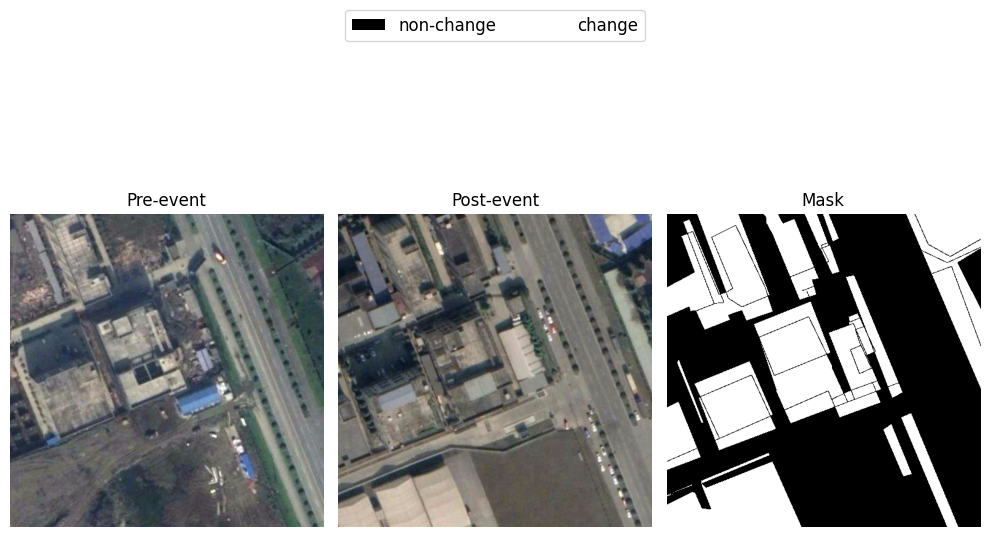

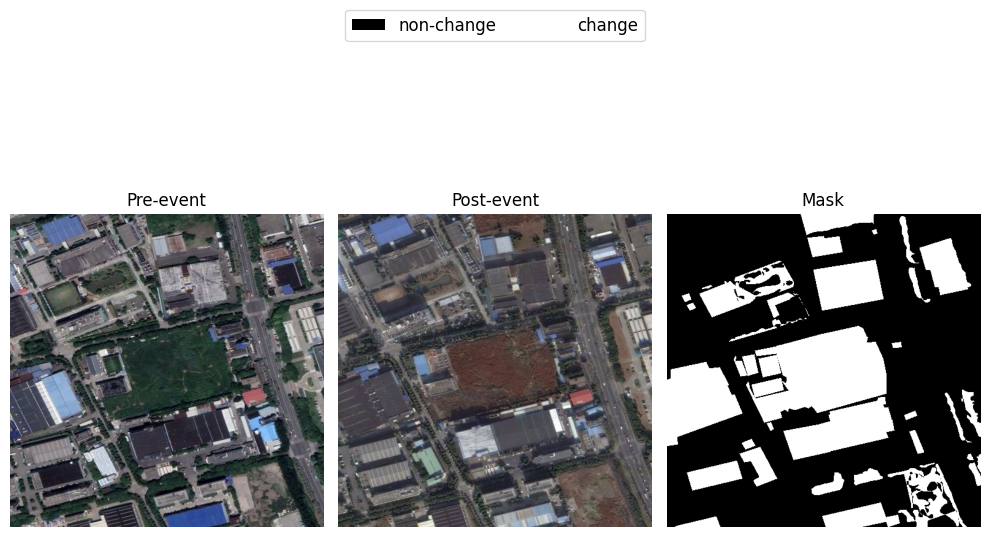

In [ ]:
dataset_config = {
    "data_dir" : "./data/second/SECOND_train_set/",
    "task_type": "binary"
}
dataset = SECONDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(22);

## Load training and test data

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/second/SECOND_train_set/",
    "task_type": "binary",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = SECONDDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/second/SECOND_total_test/test/",
    "task_type": "binary",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = SECONDDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(2968, 1694)

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/second"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [14]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-27 07:45:55,503 INFO Starting training.
training: 100%|██████████| 93/93 [13:05<00:00,  8.44s/it]
2026-01-27 07:59:00,684 INFO epoch: 1, loss:  0.24897
testing on train set: 100%|██████████| 93/93 [13:52<00:00,  8.96s/it]
2026-01-27 08:12:54,661 INFO Accuracy:0.7996400437265072, Accuracy per Class:[0.77688941 0.82239068], Precision Micro:0.7758975922006943, Precision Macro:0.4686265064869699, Precision Weighted:0.6640477200955185, Precision per Class:[0.77789149 0.15936152], Recall Micro:0.814899962910416, Recall Macro:0.5004949336979855, Recall Weighted:0.8148999629104159, Recall per Class:[0.99805845 0.00293142], F1_score Micro:0.7949206573459494, F1_score Macro:0.4400423520172513, F1_score Weighted:0.7144626316450274, F1_score per Class:[0.87432777 0.00575693], IOU:0.6596417590191427, IOU mean:0.38980145030617147, IOU per Class:[0.77671612 0.00288678]
training: 100%|██████████| 93/93 [13:58<00:00,  9.01s/it]
2026-01-27 08:26:52,676 INFO epoch: 2, loss:  0.21945
testing on tr